# AcademiQ - Notebook 04: Academic Performance Classification

This notebook discretizes continuous exam scores into three balanced academic performance categories based on training set tertiles:
- **Developing** ($\\le 33.3\\%$ percentile)
- **Proficient** ($33.3\\% - 66.7\\%$ percentile)
- **Advanced** ($> 66.7\\%$ percentile)

We benchmark six supervised classification algorithms using complete preprocessing pipelines to avoid data leakage.


In [1]:
import os
from pathlib import Path

def get_project_root():
    current = Path.cwd().resolve()
    for candidate in [current, current.parent, current.parent.parent]:
        if (candidate / "data" / "raw").exists() or (candidate / "requirements.txt").exists():
            return candidate
    return current

PROJECT_ROOT = get_project_root()
os.chdir(PROJECT_ROOT)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
    files = None

from sklearn.model_selection import cross_validate
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import joblib

pd.set_option("display.max_columns", None)
print("Libraries imported successfully.")


Libraries imported successfully.


In [2]:
import os
from pathlib import Path
import pandas as pd

processed_dir = PROJECT_ROOT / "data" / "processed"
train_file = processed_dir / "AcademiQ_Train_Cleaned.csv"
test_file = processed_dir / "AcademiQ_Test_Cleaned.csv"

if not train_file.exists() and os.path.exists("/content/AcademiQ_Train_Cleaned.csv"):
    train_file = Path("/content/AcademiQ_Train_Cleaned.csv")
    test_file = Path("/content/AcademiQ_Test_Cleaned.csv")

train_df = pd.read_csv(train_file)
test_df = pd.read_csv(test_file)

print("Training dataset:", train_df.shape)
print("Testing dataset:", test_df.shape)
display(train_df.head())


Training dataset: (5285, 20)
Testing dataset: (1322, 20)


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,27,79,Low,High,Yes,8,63,High,Yes,2,Low,Medium,Public,Negative,5,No,College,Moderate,Female,69
1,16,86,High,Medium,Yes,7,94,Medium,Yes,2,Low,High,Public,Neutral,3,No,High School,Moderate,Female,69
2,22,87,Low,Medium,No,8,83,Low,Yes,1,Low,Medium,Public,Neutral,1,No,College,Far,Male,66
3,18,100,High,Medium,Yes,10,86,Medium,Yes,1,Medium,Medium,Public,Neutral,3,No,High School,Near,Male,72
4,35,78,High,Low,Yes,10,99,Medium,Yes,1,Low,Medium,Private,Positive,2,No,High School,Near,Male,72


In [3]:
target = "Exam_Score"

X_train = train_df.drop(columns=[target])
X_test = test_df.drop(columns=[target])

y_train_score = train_df[target]
y_test_score = test_df[target]

print("Features:", X_train.shape)
print("Training scores:", y_train_score.shape)
print("Testing scores:", y_test_score.shape)

Features: (5285, 19)
Training scores: (5285,)
Testing scores: (1322,)


In [4]:
lower_threshold = y_train_score.quantile(1/3)
upper_threshold = y_train_score.quantile(2/3)

print("Developing / Proficient threshold:", lower_threshold)
print("Proficient / Advanced threshold:", upper_threshold)

if lower_threshold >= upper_threshold:
    raise ValueError(
        "Thresholds are not distinct. "
        "A different category strategy is required."
    )

bins = [-np.inf, lower_threshold, upper_threshold, np.inf]

labels = [
    "Developing",
    "Proficient",
    "Advanced"
]

y_train = pd.cut(
    y_train_score,
    bins=bins,
    labels=labels,
    include_lowest=True
)

y_test = pd.cut(
    y_test_score,
    bins=bins,
    labels=labels,
    include_lowest=True
)

print("Training category distribution:")
display(y_train.value_counts().sort_index())

print("\nTesting category distribution:")
display(y_test.value_counts().sort_index())

Developing / Proficient threshold: 66.0
Proficient / Advanced threshold: 69.0
Training category distribution:


Exam_Score
Developing    2315
Proficient    1693
Advanced      1277
Name: count, dtype: int64


Testing category distribution:


Exam_Score
Developing    567
Proficient    407
Advanced      348
Name: count, dtype: int64

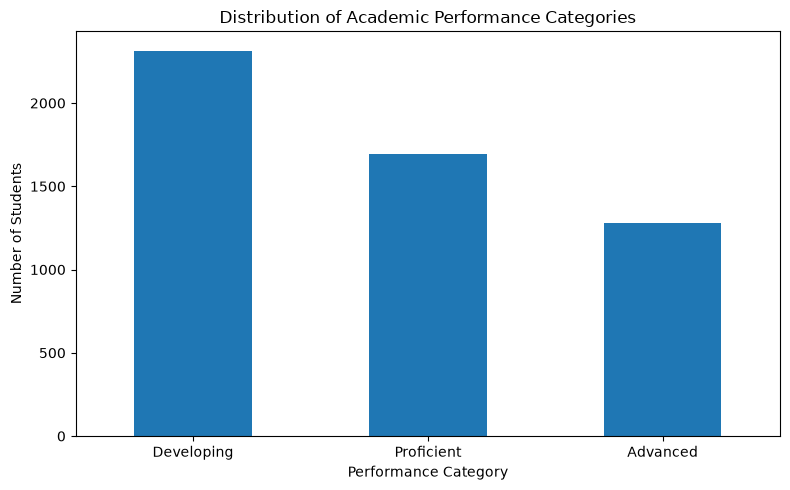

In [5]:
plt.figure(figsize=(8, 5))

y_train.value_counts().reindex(labels).plot(
    kind="bar"
)

plt.title("Distribution of Academic Performance Categories")
plt.xlabel("Performance Category")
plt.ylabel("Number of Students")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [6]:
numerical_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)

Numerical features: ['Hours_Studied', 'Attendance', 'Sleep_Hours', 'Previous_Scores', 'Tutoring_Sessions', 'Physical_Activity']
Categorical features: ['Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Motivation_Level', 'Internet_Access', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender']


C:\Users\mansi\AppData\Local\Temp\ipykernel_5856\2989966197.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(


In [7]:
numeric_pipeline = Pipeline(
    steps=[
        ("scaler", MinMaxScaler())
    ]
)

categorical_pipeline = Pipeline(
    steps=[
        (
            "encoder",
            OneHotEncoder(handle_unknown="ignore")
        )
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, numerical_features),
        ("cat", categorical_pipeline, categorical_features)
    ]
)

print("Preprocessing pipeline created.")

Preprocessing pipeline created.


In [8]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=42
    ),

    "K-Nearest Neighbors": KNeighborsClassifier(
        n_neighbors=5
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),

    "Naive Bayes": GaussianNB(),

    "Support Vector Machine": SVC(
        kernel="rbf"
    )
}

print("Six classification models defined.")

Six classification models defined.


In [9]:
classification_models = {}

for name, classifier in models.items():

    classification_models[name] = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("classifier", classifier)
        ]
    )

print("All classification pipelines created.")

All classification pipelines created.


In [10]:
for name, model in classification_models.items():

    model.fit(X_train, y_train)

    print(name, "trained successfully.")

Logistic Regression trained successfully.
K-Nearest Neighbors trained successfully.
Decision Tree trained successfully.
Random Forest trained successfully.
Naive Bayes trained successfully.
Support Vector Machine trained successfully.


In [11]:
results = []

predictions = {}

for name, model in classification_models.items():

    y_pred = model.predict(X_test)

    predictions[name] = y_pred

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, y_pred, average="macro", zero_division=0
        )
    })

classification_results = pd.DataFrame(results)

display(
    classification_results.round(4)
)

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.9508,0.9515,0.9476,0.9492
1,K-Nearest Neighbors,0.5212,0.4909,0.5044,0.4934
2,Decision Tree,0.6989,0.6890,0.6863,0.6876
3,Random Forest,0.8139,0.8232,0.7980,0.8071
4,Naive Bayes,0.6339,0.6183,0.6337,0.6175
5,Support Vector Machine,0.8616,0.8684,0.8512,0.8565


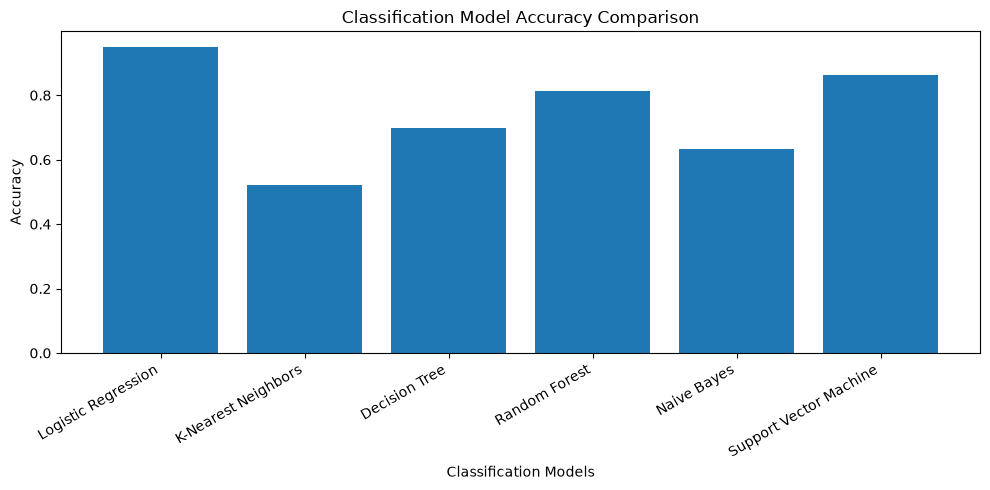

In [12]:
plt.figure(figsize=(10, 5))

plt.bar(
    classification_results["Model"],
    classification_results["Accuracy"]
)

plt.title("Classification Model Accuracy Comparison")
plt.xlabel("Classification Models")
plt.ylabel("Accuracy")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

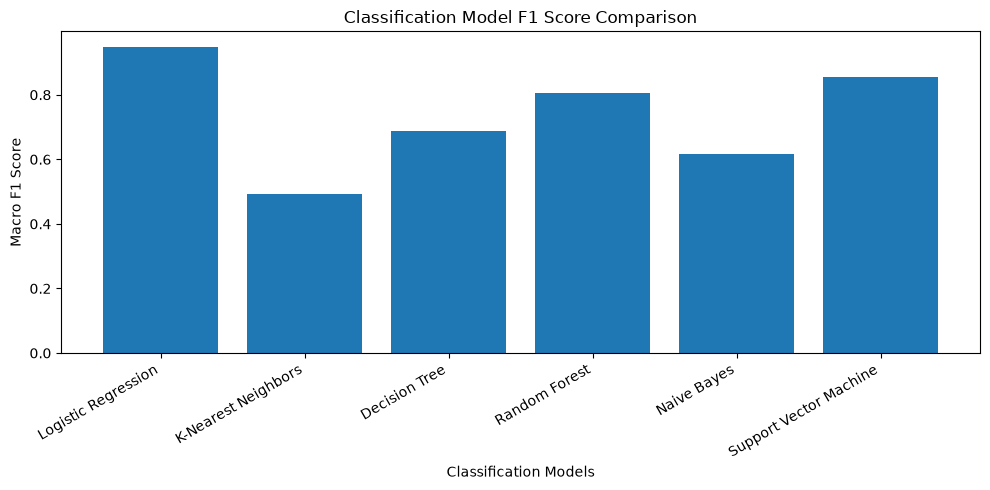

In [13]:
plt.figure(figsize=(10, 5))

plt.bar(
    classification_results["Model"],
    classification_results["F1 Score"]
)

plt.title("Classification Model F1 Score Comparison")
plt.xlabel("Classification Models")
plt.ylabel("Macro F1 Score")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

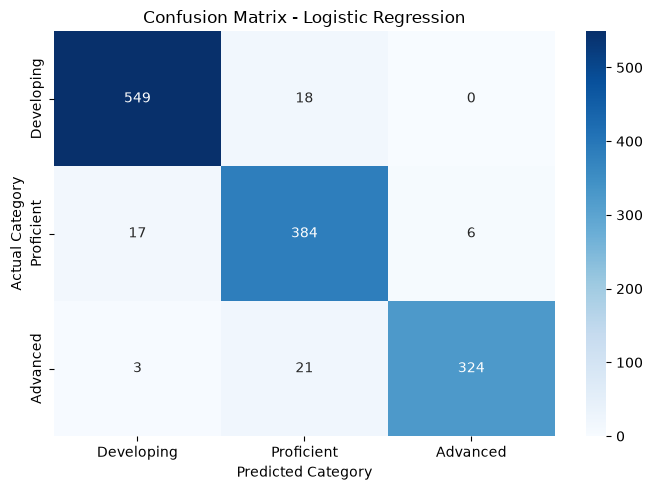

Best model: Logistic Regression


In [14]:
best_model_name = classification_results.loc[
    classification_results["F1 Score"].idxmax(),
    "Model"
]

best_model = classification_models[best_model_name]

best_predictions = predictions[best_model_name]

cm = confusion_matrix(
    y_test,
    best_predictions,
    labels=labels
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.title(f"Confusion Matrix - {best_model_name}")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.tight_layout()
plt.show()

print("Best model:", best_model_name)

In [15]:
print(
    classification_report(
        y_test,
        best_predictions,
        labels=labels,
        zero_division=0
    )
)

              precision    recall  f1-score   support

  Developing       0.96      0.97      0.97       567
  Proficient       0.91      0.94      0.93       407
    Advanced       0.98      0.93      0.96       348

    accuracy                           0.95      1322
   macro avg       0.95      0.95      0.95      1322
weighted avg       0.95      0.95      0.95      1322



In [16]:
cv_results = []

for name, model in classification_models.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=5,
        scoring={
            "Accuracy": "accuracy",
            "Precision": "precision_macro",
            "Recall": "recall_macro",
            "F1": "f1_macro"
        },
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "Mean Accuracy": scores["test_Accuracy"].mean(),
        "Mean Precision": scores["test_Precision"].mean(),
        "Mean Recall": scores["test_Recall"].mean(),
        "Mean F1 Score": scores["test_F1"].mean()
    })

cv_comparison = pd.DataFrame(cv_results)

display(cv_comparison.round(4))

,Model,Mean Accuracy,Mean Precision,Mean Recall,Mean F1 Score
0,Logistic Regression,0.9446,0.9453,0.9386,0.9415
1,K-Nearest Neighbors,0.5033,0.4708,0.4826,0.4719
2,Decision Tree,0.6956,0.6845,0.6831,0.6834
3,Random Forest,0.8032,0.8041,0.7831,0.7909
4,Naive Bayes,0.6238,0.5970,0.6259,0.5991
5,Support Vector Machine,0.8445,0.8529,0.8277,0.8355


In [17]:
import os
results_clf_dir = PROJECT_ROOT / "results" / "classification"
results_clf_dir.mkdir(parents=True, exist_ok=True)

classification_results.to_csv(results_clf_dir / "AcademiQ_Classification_Test_Results.csv", index=False)
cv_comparison.to_csv(results_clf_dir / "AcademiQ_Classification_CV_Results.csv", index=False)

print("Classification results saved successfully to results/classification/.")


Classification results saved successfully to results/classification/.


In [18]:
thresholds_df = pd.DataFrame({
    "Category": [
        "Developing",
        "Proficient",
        "Advanced"
    ],
    "Lower_Bound": [
        float("-inf"),
        float(lower_threshold),
        float(upper_threshold)
    ],
    "Upper_Bound": [
        float(lower_threshold),
        float(upper_threshold),
        float("inf")
    ]
})

results_clf_dir = PROJECT_ROOT / "results" / "classification"
results_clf_dir.mkdir(parents=True, exist_ok=True)
thresholds_df.to_csv(results_clf_dir / "AcademiQ_Performance_Category_Thresholds.csv", index=False)
display(thresholds_df)
print("Thresholds saved successfully to results/classification/.")


,Category,Lower_Bound,Upper_Bound
0,Developing,-inf,66.0
1,Proficient,66.0,69.0
2,Advanced,69.0,inf


Thresholds saved successfully to results/classification/.


In [19]:
models_dir = PROJECT_ROOT / "models"
models_dir.mkdir(parents=True, exist_ok=True)

for model_name, pipeline in classification_models.items():
    filename = model_name.lower().replace(" ", "_").replace("-", "_")
    joblib.dump(pipeline, models_dir / f"AcademiQ_{filename}.pkl")
    print(f"Saved: models/AcademiQ_{filename}.pkl")


Saved: models/AcademiQ_logistic_regression.pkl
Saved: models/AcademiQ_k_nearest_neighbors.pkl
Saved: models/AcademiQ_decision_tree.pkl
Saved: models/AcademiQ_random_forest.pkl
Saved: models/AcademiQ_naive_bayes.pkl
Saved: models/AcademiQ_support_vector_machine.pkl


In [20]:
print("========== CLASSIFICATION SUMMARY ==========")

print("\nBest model based on test Macro F1:")
print(best_model_name)

print("\nTest performance:")
display(
    classification_results.sort_values(
        by="F1 Score",
        ascending=False
    ).round(4)
)

print("\nCross-validation performance:")
display(
    cv_comparison.sort_values(
        by="Mean F1 Score",
        ascending=False
    ).round(4)
)

y_train = y_train.astype(str)
y_test = y_test.astype(str)

========== CLASSIFICATION SUMMARY ==========

Best model based on test Macro F1:
Logistic Regression

Test performance:


,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.9508,0.9515,0.9476,0.9492
5,Support Vector Machine,0.8616,0.8684,0.8512,0.8565
3,Random Forest,0.8139,0.8232,0.7980,0.8071
2,Decision Tree,0.6989,0.6890,0.6863,0.6876
4,Naive Bayes,0.6339,0.6183,0.6337,0.6175
1,K-Nearest Neighbors,0.5212,0.4909,0.5044,0.4934



Cross-validation performance:


,Model,Mean Accuracy,Mean Precision,Mean Recall,Mean F1 Score
0,Logistic Regression,0.9446,0.9453,0.9386,0.9415
5,Support Vector Machine,0.8445,0.8529,0.8277,0.8355
3,Random Forest,0.8032,0.8041,0.7831,0.7909
2,Decision Tree,0.6956,0.6845,0.6831,0.6834
4,Naive Bayes,0.6238,0.5970,0.6259,0.5991
1,K-Nearest Neighbors,0.5033,0.4708,0.4826,0.4719


In [21]:
if IN_COLAB and files is not None:
    try:
        files.download(str(PROJECT_ROOT / "results" / "classification" / "AcademiQ_Classification_Test_Results.csv"))
        files.download(str(PROJECT_ROOT / "results" / "classification" / "AcademiQ_Classification_CV_Results.csv"))
    except Exception as e:
        print(f"Colab download skipped: {e}")
else:
    print("Classification results saved in results/classification/.")


Classification results saved in results/classification/.
